# EDA v1 — Phân khúc khách hàng và nhận diện khách hàng có giá trị cao

**Ngô Nguyên — MSSV 3124411191 — T03 — Sprint 1 (02–03/11/2026).**

## 1. Giới thiệu

Notebook thực hiện **phân tích khám phá ban đầu** trên tệp Online Retail II
trong repository: kiểm tra phạm vi từng sheet, chất lượng dữ liệu, thống kê mô tả,
số hóa đơn theo thời gian/quốc gia và phân phối số lượng, đơn giá.
Kết quả phục vụ bàn giao tiền xử lý và chuẩn bị đặc trưng RFM;
chưa xây dựng RFM, huấn luyện phân cụm hay dự đoán giá trị khách hàng tương lai.

**Kết quả chính của lần kiểm tra nguồn** `bcbe73b3…df2e980`:
1.067.371 dòng từ 2 sheet, 53.628 mã hóa đơn và 5.942 mã khách hàng hợp lệ về hình thức.
Thiếu Customer ID ở 22,77% số dòng; có 34.335 dòng trùng dư, gồm 22.202 dòng tăng thêm khi gộp sheet.
Đây là số liệu của phiên bản tệp được kiểm tra; khi nguồn đổi, cần cập nhật tóm tắt này
sau khi chạy lại và kiểm tra checksum ở mục 10. Các nhận xét ở từng phần bên dưới được tính động.

Nguồn dữ liệu và từ điển: [Chen, D. (2012), Online Retail II, UCI](https://archive.ics.uci.edu/dataset/502/online+retail+ii),
[DOI 10.24432/C5CG6D](https://doi.org/10.24432/C5CG6D).
Theo UCI, đây là dữ liệu giao dịch của một nhà bán lẻ trực tuyến đăng ký tại Anh;
đơn giá tính bằng GBP; mã hóa đơn bắt đầu bằng `C` biểu thị hủy.
Các số liệu bên dưới được **tính từ tệp cục bộ**, không lấy số thống kê công bố để thay kết quả chạy.

**Phạm vi:** đọc và kiểm tra **tất cả các sheet**. Nếu cấu trúc cột tương thích,
gộp toàn bộ dòng theo chiều dọc trong bộ nhớ; dừng với thông báo nếu không tương thích.
Không bỏ dòng thiếu mã khách hàng, dòng hủy, giá trị âm, dòng trùng hoặc ngoại lai trong EDA v1.

## 2. Chuẩn bị môi trường và đọc dữ liệu

### 2.1. Quy ước và giả định

- Một dòng biểu diễn một mặt hàng/bút toán trên hóa đơn; nhiều dòng có thể thuộc cùng hóa đơn.
  `Invoice` là mã chứng từ, gồm cả chứng từ hủy/điều chỉnh; không đồng nghĩa với đơn mua thành công.
  Khách hàng được nhận diện bằng `Customer ID`, có thể có nhiều hóa đơn.
- Mã hóa đơn, mã sản phẩm và mã khách hàng là **định danh**, không phải biến liên tục.
- Mã khách hàng “hợp lệ về hình thức” được định nghĩa ở đây: chuyển được sang số hữu hạn,
  nguyên dương, có 5 chữ số theo từ điển UCI. Điều này không xác nhận danh tính ngoài hệ thống.
- Thời gian giữ nguyên như Excel; không có thông tin múi giờ để quy đổi.
- `LineValue = Quantity × Price` là giá trị đại số của dòng (GBP), chưa xác nhận doanh thu thuần,
  lợi nhuận hay giá trị vòng đời. Chưa chốt chính sách hủy/hoàn trả và ngoại lai.

In [1]:
from pathlib import Path
import hashlib
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 14)
pd.set_option('display.max_rows', 45)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 13, 'axes.labelsize': 11,
    'figure.dpi': 110, 'savefig.dpi': 150,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False,
})
BLUE, GOLD, GRAY = '#245B84', '#B46A11', '#5A6068'

def vn_int(value):
    return f'{int(value):,}'.replace(',', '.')

def note(text):
    display(Markdown('**Nhận xét.** ' + text))

def show_table(frame, formats=None):
    display(frame.style.format(formats or {}, na_rep='—').hide(axis='index'))

def sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def find_project(start):
    for parent in [start, *start.parents]:
        for candidate in (parent, parent / 'project'):
            if (candidate / 'data/raw/online_retail_II.xlsx').is_file() and (candidate / 'requirements.txt').is_file():
                return candidate
    raise FileNotFoundError('Mở notebook từ repository hoặc project/notebooks/01_eda; cần data/raw/online_retail_II.xlsx.')

PROJECT_DIR = find_project(Path.cwd().resolve())
DATA_PATH = PROJECT_DIR / 'data/raw/online_retail_II.xlsx'
source_hash_before = sha256(DATA_PATH)
environment = {'Python': platform.python_version(), **{
    package: version(package) for package in
    ['numpy', 'pandas', 'matplotlib', 'openpyxl', 'nbformat', 'nbclient', 'ipykernel']
}}
show_table(pd.DataFrame(environment.items(), columns=['Thành phần', 'Phiên bản']))
note('Đường dẫn được tìm từ thư mục hiện tại và các thư mục cha; không chứa đường dẫn tuyệt đối riêng của máy. '
     'Notebook chỉ đọc Excel và xử lý trong bộ nhớ. Phiên bản ở bảng trên là môi trường thực sự chạy.')

Thành phần,Phiên bản
Python,3.12.15
numpy,2.5.4
pandas,3.1.0
matplotlib,3.11.2
openpyxl,3.1.5
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


**Nhận xét.** Đường dẫn được tìm từ thư mục hiện tại và các thư mục cha; không chứa đường dẫn tuyệt đối riêng của máy. Notebook chỉ đọc Excel và xử lý trong bộ nhớ. Phiên bản ở bảng trên là môi trường thực sự chạy.

### 2.2. Kiểm kê workbook và khả năng gộp

Kiểm tra tên/cấu trúc cột, kiểu dữ liệu suy luận và mốc thời gian của từng sheet trước khi gộp.
`errors='coerce'` chỉ dùng trên bản sao ngày để phát hiện giá trị không phân tích được;
không sửa cột ngày trong dữ liệu gốc.

In [2]:
with pd.ExcelFile(DATA_PATH, engine='openpyxl') as workbook:
    sheet_names = workbook.sheet_names
    sheets = {name: pd.read_excel(workbook, sheet_name=name) for name in sheet_names}

original_columns = list(sheets[sheet_names[0]].columns)
required_columns = {'Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country'}
if set(original_columns) != required_columns:
    raise ValueError(f'Cấu trúc nguồn cần được xem xét lại: {original_columns}')
if any(set(part.columns) != set(original_columns) for part in sheets.values()):
    raise ValueError('Các sheet khác cấu trúc; không tự động bỏ cột hoặc sheet. Cần rà soát trước khi gộp.')

sheet_records = []
dtype_records = []
for name, part in sheets.items():
    dates = pd.to_datetime(part['InvoiceDate'], errors='coerce')
    sheet_records.append({
        'Sheet': name, 'Số dòng': len(part), 'Số cột': part.shape[1],
        'Từ': dates.min(), 'Đến': dates.max(),
        'Ngày thiếu': int(part['InvoiceDate'].isna().sum()),
        'Ngày lỗi khác thiếu': int((part['InvoiceDate'].notna() & dates.isna()).sum()),
    })
    dtype_records.extend({'Sheet': name, 'Cột': column, 'Kiểu dữ liệu': str(part[column].dtype)} for column in original_columns)
sheet_profile = pd.DataFrame(sheet_records)
show_table(sheet_profile)
note('Đã đọc các sheet: ' + ', '.join(sheet_names) + '. Mọi sheet có cùng tập cột; thứ tự được căn theo sheet đầu. '
     'Khoảng thời gian có thể chồng lấn: phần trùng giữa sheet được kiểm tra riêng ở mục 4, chưa loại bỏ.')

Sheet,Số dòng,Số cột,Từ,Đến,Ngày thiếu,Ngày lỗi khác thiếu
Year 2009-2010,525461,8,2009-12-01 07:45:00,2010-12-09 20:01:00,0,0
Year 2010-2011,541910,8,2010-12-01 08:26:00,2011-12-09 12:50:00,0,0


**Nhận xét.** Đã đọc các sheet: Year 2009-2010, Year 2010-2011. Mọi sheet có cùng tập cột; thứ tự được căn theo sheet đầu. Khoảng thời gian có thể chồng lấn: phần trùng giữa sheet được kiểm tra riêng ở mục 4, chưa loại bỏ.

In [3]:
sheet_dtypes = pd.DataFrame(dtype_records).pivot(index='Cột', columns='Sheet', values='Kiểu dữ liệu').reset_index()
show_table(sheet_dtypes)
dtype_compatible = all(sheets[name][column].dtype == sheets[sheet_names[0]][column].dtype
                       for name in sheet_names for column in original_columns)
if not dtype_compatible:
    raise TypeError('Kiểu dữ liệu giữa sheet khác nhau; cần quyết định chuyển kiểu trước khi gộp.')
note('Kiểu dữ liệu suy luận tương thích giữa các sheet. Các mã có thể gồm số và chữ nên sẽ có cột định danh phân tích riêng; '
     'không tính trung bình mã khách hàng hoặc mã hóa đơn.')

raw = pd.concat([sheets[name].loc[:, original_columns] for name in sheet_names], ignore_index=True)
source_sheet = pd.concat([pd.Series(name, index=range(len(sheets[name]))) for name in sheet_names], ignore_index=True)
assert len(raw) == sum(len(part) for part in sheets.values())
display(raw.head(5))
note(f'Bảng xem trước giữ tên cột của Excel. Dữ liệu gộp có {vn_int(len(raw))} dòng và {len(original_columns)} cột nguồn. '
     'Tên sheet được giữ trong biến riêng, không làm thay đổi định nghĩa dòng trùng trên 8 cột nguồn.')

Cột,Year 2009-2010,Year 2010-2011
Country,str,str
Customer ID,float64,float64
Description,object,object
Invoice,object,object
InvoiceDate,datetime64[us],datetime64[us]
Price,float64,float64
Quantity,int64,int64
StockCode,object,object


**Nhận xét.** Kiểu dữ liệu suy luận tương thích giữa các sheet. Các mã có thể gồm số và chữ nên sẽ có cột định danh phân tích riêng; không tính trung bình mã khách hàng hoặc mã hóa đơn.

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,"13,085.000",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,"13,085.000",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,"13,085.000",United Kingdom


**Nhận xét.** Bảng xem trước giữ tên cột của Excel. Dữ liệu gộp có 1.067.371 dòng và 8 cột nguồn. Tên sheet được giữ trong biến riêng, không làm thay đổi định nghĩa dòng trùng trên 8 cột nguồn.

## 3. Tổng quan dữ liệu

### 3.1. Định danh và phạm vi quan sát

Tạo bản sao `eda`: mã được chuyển sang chuỗi và bỏ khoảng trắng ở hai đầu,
ngày/numeric được chuyển kiểu có kiểm tra. Các cột bổ sung chỉ phục vụ EDA.
`StockCode` khác rỗng được đếm như **mã hàng**, vì có thể chứa bưu phí/dịch vụ/điều chỉnh,
chưa thể đồng nhất toàn bộ với sản phẩm hàng hóa.

In [4]:
def normalized_identifier(series):
    return series.astype('string').str.strip().str.replace(r'(?<=\d)\.0$', '', regex=True).replace('', pd.NA)

eda = raw.copy()
eda['InvoiceKey'] = normalized_identifier(raw['Invoice'])
eda['StockKey'] = normalized_identifier(raw['StockCode'])
eda['CountryKey'] = raw['Country'].astype('string').str.strip().replace('', pd.NA)
eda['InvoiceDateParsed'] = pd.to_datetime(raw['InvoiceDate'], errors='coerce')
for column in ['Quantity', 'Price', 'Customer ID']:
    eda[column] = pd.to_numeric(raw[column], errors='coerce')
customer = eda['Customer ID']
valid_customer = customer.notna() & np.isfinite(customer) & customer.between(10000, 99999) & customer.mod(1).eq(0)
cancelled = eda['InvoiceKey'].str.upper().str.startswith('C', na=False)
eda['LineValue'] = eda['Quantity'] * eda['Price']
n_rows = len(raw)
n_invoices = int(eda['InvoiceKey'].nunique())
n_customers = int(customer[valid_customer].nunique())
n_countries = int(eda['CountryKey'].nunique())
n_stockcodes = int(eda['StockKey'].nunique())
date_min, date_max = eda['InvoiceDateParsed'].min(), eda['InvoiceDateParsed'].max()
overview = pd.DataFrame([
    ('Dòng giao dịch thô', n_rows), ('Cột nguồn', len(original_columns)),
    ('Khách hàng có mã hợp lệ về hình thức', n_customers),
    ('Dòng có mã khách hàng hợp lệ về hình thức', int(valid_customer.sum())),
    ('Mã hóa đơn duy nhất (gồm hủy/điều chỉnh)', n_invoices),
    ('Nhãn quốc gia duy nhất', n_countries), ('Mã hàng duy nhất (chưa phân loại dịch vụ)', n_stockcodes),
    ('Thời điểm đầu', str(date_min)), ('Thời điểm cuối', str(date_max)),
], columns=['Chỉ tiêu', 'Giá trị'])
show_table(overview)
show_table(pd.DataFrame({'Cột nguồn': raw.columns, 'Kiểu dữ liệu sau gộp': raw.dtypes.astype(str).values}))
note(f'{vn_int(n_rows)} dòng không phải {vn_int(n_rows)} lần mua: có {vn_int(n_invoices)} mã hóa đơn và '
     f'{vn_int(n_customers)} khách hàng nhận diện được theo quy tắc hình thức. '
     f'Các thống kê dùng toàn bộ sheet, từ {date_min:%d/%m/%Y %H:%M} đến {date_max:%d/%m/%Y %H:%M}; '
     'số quốc gia là số nhãn trong nguồn, chưa chuẩn hóa địa lý.')

Chỉ tiêu,Giá trị
Dòng giao dịch thô,1067371
Cột nguồn,8
Khách hàng có mã hợp lệ về hình thức,5942
Dòng có mã khách hàng hợp lệ về hình thức,824364
Mã hóa đơn duy nhất (gồm hủy/điều chỉnh),53628
Nhãn quốc gia duy nhất,43
Mã hàng duy nhất (chưa phân loại dịch vụ),5304
Thời điểm đầu,2009-12-01 07:45:00
Thời điểm cuối,2011-12-09 12:50:00


Cột nguồn,Kiểu dữ liệu sau gộp
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
Price,float64
Customer ID,float64
Country,str


**Nhận xét.** 1.067.371 dòng không phải 1.067.371 lần mua: có 53.628 mã hóa đơn và 5.942 khách hàng nhận diện được theo quy tắc hình thức. Các thống kê dùng toàn bộ sheet, từ 01/12/2009 07:45 đến 09/12/2011 12:50; số quốc gia là số nhãn trong nguồn, chưa chuẩn hóa địa lý.

## 4. Kiểm tra chất lượng dữ liệu

### 4.1. Giá trị thiếu và chuyển kiểu

Tỷ lệ thiếu dùng mẫu số là **toàn bộ dòng thô**. Tách giá trị thực sự thiếu,
chuỗi rỗng sau trim và lỗi chuyển kiểu, không tự gán giá trị thay thế.

In [5]:
missing = pd.DataFrame({
    'Cột': original_columns,
    'Số giá trị thiếu': raw.isna().sum().values,
    'Tỷ lệ thiếu (%)': raw.isna().mean().mul(100).values,
    'Chuỗi rỗng sau trim': [int(raw[col].astype('string').str.strip().eq('').fillna(False).sum()) for col in original_columns],
}).sort_values('Số giá trị thiếu', ascending=False)
show_table(missing, {'Tỷ lệ thiếu (%)': '{:.3f}'})
conversion_errors = {col: int((raw[col].notna() & eda[col].isna()).sum()) for col in ['Quantity', 'Price', 'Customer ID']}
date_missing = int(raw['InvoiceDate'].isna().sum())
date_invalid = int((raw['InvoiceDate'].notna() & eda['InvoiceDateParsed'].isna()).sum())
customer_missing = int(raw['Customer ID'].isna().sum())
customer_invalid_nonmissing = int((raw['Customer ID'].notna() & ~valid_customer).sum())
note(f'Customer ID thiếu {vn_int(customer_missing)} dòng ({customer_missing / n_rows:.2%}); '
     f'có {vn_int(customer_invalid_nonmissing)} mã không thiếu nhưng không đạt quy tắc hình thức. '
     'Không gán toàn bộ khách hàng thiếu mã thành một khách hàng. '
     f'Lỗi chuyển số: {conversion_errors}. Ngày thiếu: {vn_int(date_missing)}; ngày không thiếu nhưng không phân tích được: {vn_int(date_invalid)}.')

quality_by_sheet = pd.DataFrame([{
    'Sheet': name, 'Dòng': len(part),
    'Thiếu Customer ID': int(part['Customer ID'].isna().sum()),
    'Thiếu Customer ID (%)': part['Customer ID'].isna().mean() * 100,
    'Dòng trùng dư trong sheet': int(part.duplicated(subset=original_columns).sum()),
} for name, part in sheets.items()])
show_table(quality_by_sheet, {'Thiếu Customer ID (%)': '{:.3f}'})
note('So sánh theo sheet giúp tránh coi mức thiếu/trùng của toàn bộ workbook là đồng đều theo thời gian. '
     'Mỗi dòng trùng dư được tính sau bản ghi đầu tiên; chưa kết luận các bản ghi giống nhau là lỗi nghiệp vụ.')

Cột,Số giá trị thiếu,Tỷ lệ thiếu (%),Chuỗi rỗng sau trim
Customer ID,243007,22.767,0
Description,4382,0.411,0
StockCode,0,0.000,0
Invoice,0,0.000,0
Quantity,0,0.000,0
InvoiceDate,0,0.000,0
Price,0,0.000,0
Country,0,0.000,0


**Nhận xét.** Customer ID thiếu 243.007 dòng (22.77%); có 0 mã không thiếu nhưng không đạt quy tắc hình thức. Không gán toàn bộ khách hàng thiếu mã thành một khách hàng. Lỗi chuyển số: {'Quantity': 0, 'Price': 0, 'Customer ID': 0}. Ngày thiếu: 0; ngày không thiếu nhưng không phân tích được: 0.

Sheet,Dòng,Thiếu Customer ID,Thiếu Customer ID (%),Dòng trùng dư trong sheet
Year 2009-2010,525461,107927,20.539,6865
Year 2010-2011,541910,135080,24.927,5268


**Nhận xét.** So sánh theo sheet giúp tránh coi mức thiếu/trùng của toàn bộ workbook là đồng đều theo thời gian. Mỗi dòng trùng dư được tính sau bản ghi đầu tiên; chưa kết luận các bản ghi giống nhau là lỗi nghiệp vụ.

### 4.2. Dòng trùng và chồng lấn giữa sheet

“Trùng dư” = `duplicated(keep='first')` trên **8 cột gốc**, không gồm tên sheet hay biến tạo thêm.
“Dòng thuộc nhóm trùng” = `duplicated(keep=False)`.
Các dòng giống nhau có thể là bản sao hoặc nghiệp vụ lặp; chưa áp dụng xóa.

In [6]:
duplicate_excess = int(raw.duplicated(subset=original_columns).sum())
duplicate_members = int(raw.duplicated(subset=original_columns, keep=False).sum())
within_sheet_excess = int(quality_by_sheet['Dòng trùng dư trong sheet'].sum())
cross_sheet_excess = duplicate_excess - within_sheet_excess

# Chỉ giảm về các mẫu dòng riêng biệt để kiểm tra nguồn, không thay dữ liệu EDA.
source_patterns = raw.assign(SourceSheet=source_sheet).drop_duplicates(subset=original_columns + ['SourceSheet'])
patterns_across_sheets = source_patterns.groupby(original_columns, dropna=False, sort=False)['SourceSheet'].nunique()
cross_sheet_patterns = int(patterns_across_sheets.gt(1).sum())
show_table(pd.DataFrame([
    ('Dòng trùng dư toàn workbook', duplicate_excess),
    ('Dòng thuộc nhóm trùng toàn workbook', duplicate_members),
    ('Tổng dòng trùng dư bên trong từng sheet', within_sheet_excess),
    ('Dòng trùng dư tăng thêm khi gộp sheet', cross_sheet_excess),
    ('Mẫu dòng giống hệt xuất hiện ở nhiều sheet', cross_sheet_patterns),
], columns=['Phép kiểm tra', 'Số lượng']))

invoice_source = pd.DataFrame({'Invoice': eda['InvoiceKey'], 'Sheet': source_sheet}).dropna().drop_duplicates()
shared_invoice_count = int(invoice_source.groupby('Invoice')['Sheet'].nunique().gt(1).sum())
note(f'Có {vn_int(duplicate_excess)} dòng trùng dư ({duplicate_excess / n_rows:.2%}) và '
     f'{vn_int(cross_sheet_patterns)} mẫu dòng giống hệt ở nhiều sheet; '
     f'{vn_int(shared_invoice_count)} mã hóa đơn xuất hiện ở nhiều sheet. '
     'Chồng lấn có thể làm tăng số dòng và tổng giá trị khi cộng trực tiếp; đếm nunique trên dữ liệu gộp '
     'giúp một mã hóa đơn trong cùng tháng/quốc gia chỉ được tính một lần. Cần thống nhất chính sách trùng trước Monetary/Frequency.')

Phép kiểm tra,Số lượng
Dòng trùng dư toàn workbook,34335
Dòng thuộc nhóm trùng toàn workbook,67242
Tổng dòng trùng dư bên trong từng sheet,12133
Dòng trùng dư tăng thêm khi gộp sheet,22202
Mẫu dòng giống hệt xuất hiện ở nhiều sheet,22202


**Nhận xét.** Có 34.335 dòng trùng dư (3.22%) và 22.202 mẫu dòng giống hệt ở nhiều sheet; 1.088 mã hóa đơn xuất hiện ở nhiều sheet. Chồng lấn có thể làm tăng số dòng và tổng giá trị khi cộng trực tiếp; đếm nunique trên dữ liệu gộp giúp một mã hóa đơn trong cùng tháng/quốc gia chỉ được tính một lần. Cần thống nhất chính sách trùng trước Monetary/Frequency.

### 4.3. Hóa đơn hủy, lượng/giá không dương và tính nhất quán

Theo quy ước UCI, nhận diện hủy qua tiền tố `C` (không phân biệt hoa/thường).
Bảng dưới báo cáo cả **số dòng** và **mã hóa đơn duy nhất liên quan**;
các nhóm có thể chồng lên nhau nên không cộng các dòng trong bảng để suy ra tổng bất thường.

In [7]:
checks = {
    'Hóa đơn có tiền tố C': cancelled,
    'Quantity = 0': eda['Quantity'].eq(0),
    'Quantity < 0': eda['Quantity'].lt(0),
    'Price = 0': eda['Price'].eq(0),
    'Price < 0': eda['Price'].lt(0),
    'Quantity < 0 nhưng không có tiền tố C': eda['Quantity'].lt(0) & ~cancelled,
    'Tiền tố C nhưng Quantity >= 0': cancelled & eda['Quantity'].ge(0),
    'Không có mã khách hàng hợp lệ về hình thức': ~valid_customer,
}
quality_counts = pd.DataFrame([{
    'Dấu hiệu': name, 'Số dòng': int(mask.sum()), 'Tỷ lệ dòng (%)': mask.mean() * 100,
    'Mã hóa đơn liên quan': int(eda.loc[mask, 'InvoiceKey'].nunique()),
} for name, mask in checks.items()])
show_table(quality_counts, {'Tỷ lệ dòng (%)': '{:.3f}'})
n_cancel_rows = int(cancelled.sum())
n_cancel_invoices = int(eda.loc[cancelled, 'InvoiceKey'].nunique())
note(f'Tiền tố C xuất hiện ở {vn_int(n_cancel_rows)} dòng thuộc {vn_int(n_cancel_invoices)} mã hóa đơn. '
     'Số lượng âm có thể liên quan hoàn/hủy/điều chỉnh; dấu âm không tự chứng minh một bản ghi sai. '
     'Giá bằng 0/âm và lượng cực trị cần đối chiếu mô tả, mã hàng và hóa đơn trước khi quyết định xử lý.')

Dấu hiệu,Số dòng,Tỷ lệ dòng (%),Mã hóa đơn liên quan
Hóa đơn có tiền tố C,19494,1.826,8292
Quantity = 0,0,0.000,0
Quantity < 0,22950,2.150,11684
Price = 0,6202,0.581,5379
Price < 0,5,0.000,5
Quantity < 0 nhưng không có tiền tố C,3457,0.324,3393
Tiền tố C nhưng Quantity >= 0,1,0.000,1
Không có mã khách hàng hợp lệ về hình thức,243007,22.767,8752


**Nhận xét.** Tiền tố C xuất hiện ở 19.494 dòng thuộc 8.292 mã hóa đơn. Số lượng âm có thể liên quan hoàn/hủy/điều chỉnh; dấu âm không tự chứng minh một bản ghi sai. Giá bằng 0/âm và lượng cực trị cần đối chiếu mô tả, mã hàng và hóa đơn trước khi quyết định xử lý.

In [8]:
invoice_nonstandard = ~eda['InvoiceKey'].str.fullmatch(r'[Cc]?\d{6}', na=False)
stock_nonstandard = ~eda['StockKey'].str.fullmatch(r'\d{5}[A-Za-z]*', na=False)
invoice_groups = eda.dropna(subset=['InvoiceKey']).groupby('InvoiceKey')
invoice_country_counts = invoice_groups['CountryKey'].nunique()
invoice_customer_counts = invoice_groups['Customer ID'].nunique()
invoice_date_counts = invoice_groups['InvoiceDateParsed'].nunique()
invoice_month_counts = eda.assign(Month=eda['InvoiceDateParsed'].dt.to_period('M')).groupby('InvoiceKey')['Month'].nunique()
multi_country = invoice_country_counts[invoice_country_counts.gt(1)]
multi_customer = invoice_customer_counts[invoice_customer_counts.gt(1)]
multi_month = invoice_month_counts[invoice_month_counts.gt(1)]
country_changes = int((raw['Country'].astype('string') != eda['CountryKey']).fillna(False).sum())
country_unspecified = eda['CountryKey'].str.casefold().eq('unspecified').fillna(False)
other_checks = pd.DataFrame([
    ('Invoice thiếu/rỗng sau chuẩn hóa', int(eda['InvoiceKey'].isna().sum()), 'dòng'),
    ('Invoice ngoài mẫu 6 số hoặc C + 6 số', int(invoice_nonstandard.sum()), 'dòng'),
    ('Mã hàng ngoài mẫu 5 số + hậu tố chữ', int(stock_nonstandard.sum()), 'dòng'),
    ('Mã hóa đơn gắn nhiều quốc gia', len(multi_country), 'mã hóa đơn'),
    ('Mã hóa đơn gắn nhiều Customer ID không thiếu', len(multi_customer), 'mã hóa đơn'),
    ('Mã hóa đơn gắn nhiều thời điểm', int(invoice_date_counts.gt(1).sum()), 'mã hóa đơn'),
    ('Mã hóa đơn xuất hiện ở nhiều tháng', len(multi_month), 'mã hóa đơn'),
    ('Quốc gia thay đổi khi trim', country_changes, 'dòng'),
    ('Quốc gia mang nhãn Unspecified (thiếu ngữ nghĩa)', int(country_unspecified.sum()), 'dòng'),
], columns=['Phép kiểm tra', 'Số lượng', 'Đơn vị'])
show_table(other_checks)
display(eda.loc[invoice_nonstandard | stock_nonstandard, original_columns].head(10))
note(f'Có {vn_int(len(multi_country))} mã hóa đơn gắn nhiều quốc gia và {vn_int(len(multi_customer))} mã gắn nhiều khách hàng không thiếu. '
     'Các mã ngoài mẫu được xem là dấu hiệu cần phân loại (ví dụ mã dịch vụ/bút toán), không mặc định là không hợp lệ. '
     f'Có {vn_int(int(country_unspecified.sum()))} dòng quốc gia Unspecified; 43 nhãn không đồng nghĩa 43 quốc gia đã xác minh '
     '(còn có nhãn như European Community). '
     'Bảng ví dụ chỉ hiển thị tối đa 10 dòng, không đại diện toàn bộ các trường hợp.')

Phép kiểm tra,Số lượng,Đơn vị
Invoice thiếu/rỗng sau chuẩn hóa,0,dòng
Invoice ngoài mẫu 6 số hoặc C + 6 số,6,dòng
Mã hàng ngoài mẫu 5 số + hậu tố chữ,6093,dòng
Mã hóa đơn gắn nhiều quốc gia,0,mã hóa đơn
Mã hóa đơn gắn nhiều Customer ID không thiếu,0,mã hóa đơn
Mã hóa đơn gắn nhiều thời điểm,83,mã hóa đơn
Mã hóa đơn xuất hiện ở nhiều tháng,0,mã hóa đơn
Quốc gia thay đổi khi trim,0,dòng
Quốc gia mang nhãn Unspecified (thiếu ngữ nghĩa),756,dòng


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
89,489439,POST,POSTAGE,3,2009-12-01 09:28:00,18.000,"12,682.000",France
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.000,"12,636.000",USA
173,489447,POST,POSTAGE,1,2009-12-01 10:10:00,130.000,"12,362.000",Belgium
625,489526,POST,POSTAGE,6,2009-12-01 11:50:00,18.000,"12,533.000",Germany
735,C489535,D,Discount,-1,2009-12-01 12:11:00,9.000,"15,299.000",United Kingdom
736,C489535,D,Discount,-1,2009-12-01 12:11:00,19.000,"15,299.000",United Kingdom
927,C489538,POST,POSTAGE,-1,2009-12-01 12:18:00,9.580,"15,796.000",United Kingdom
1244,489557,POST,POSTAGE,4,2009-12-01 12:52:00,18.000,"12,490.000",France
2377,489597,DCGS0058,MISO PRETTY GUM,1,2009-12-01 14:28:00,0.830,NaN,United Kingdom
2378,489597,DCGS0068,DOGS NIGHT COLLAR,1,2009-12-01 14:28:00,8.650,NaN,United Kingdom


**Nhận xét.** Có 0 mã hóa đơn gắn nhiều quốc gia và 0 mã gắn nhiều khách hàng không thiếu. Các mã ngoài mẫu được xem là dấu hiệu cần phân loại (ví dụ mã dịch vụ/bút toán), không mặc định là không hợp lệ. Có 756 dòng quốc gia Unspecified; 43 nhãn không đồng nghĩa 43 quốc gia đã xác minh (còn có nhãn như European Community). Bảng ví dụ chỉ hiển thị tối đa 10 dòng, không đại diện toàn bộ các trường hợp.

## 5. Thống kê mô tả

Phân tích `Quantity`, `Price` (GBP/đơn vị), `LineValue` (GBP/dòng).
Không đưa cột định danh vào thống kê số. Tất cả dòng hủy, âm, trùng và thiếu mã khách hàng vẫn được giữ.
`LineValue` âm thường làm giảm tổng đại số; khi cả lượng và giá âm, tích có thể dương.
Tổng này chưa được coi là doanh thu đã làm sạch.

In [9]:
numeric_columns = ['Quantity', 'Price', 'LineValue']
descriptive = eda[numeric_columns].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
descriptive = descriptive.rename(columns={
    'count': 'Số quan sát', 'mean': 'Trung bình', 'std': 'Độ lệch chuẩn',
    'min': 'Nhỏ nhất', '1%': 'P01', '25%': 'Q1', '50%': 'Trung vị',
    '75%': 'Q3', '99%': 'P99', 'max': 'Lớn nhất',
})
descriptive['Độ lệch (skew)'] = eda[numeric_columns].skew()
show_table(descriptive.reset_index(names='Biến'), {col: '{:,.3f}' for col in descriptive.columns})
note('Trung bình so với trung vị và các phân vị cho thấy mức độ ảnh hưởng của đuôi phân phối. '
     + '; '.join(f'{col}: trung bình {eda[col].mean():,.3f}, trung vị {eda[col].median():,.3f}, '
                 f'min {eda[col].min():,.3f}, max {eda[col].max():,.3f}, skew {eda[col].skew():,.2f}' for col in numeric_columns)
     + '. Các cực trị là ứng viên cần rà soát, chưa có chính sách xóa ngoại lai.')
note('Quantity có skew dương, phù hợp với đuôi lớn về phía số lượng dương. '
     'Price và LineValue có skew âm trong dữ liệu thô dù trung bình lớn hơn trung vị; '
     'các giá trị âm cực lớn ảnh hưởng mạnh đến mômen bậc ba. Không nên kết luận tất cả biến đều lệch phải '
     'chỉ từ trung bình/trung vị; cần đọc đồng thời bảng cực trị và biểu đồ toàn miền.')

Biến,Số quan sát,Trung bình,Độ lệch chuẩn,Nhỏ nhất,P01,Q1,Trung vị,Q3,P99,Lớn nhất,Độ lệch (skew)
Quantity,"1,067,371.000",9.939,172.706,"-80,995.000",-3.000,1.000,3.000,10.000,100.000,"80,995.000",3.996
Price,"1,067,371.000",4.649,123.553,"-53,594.360",0.210,1.250,2.100,4.150,18.000,"38,970.000",-69.165
LineValue,"1,067,371.000",18.070,292.420,"-168,469.600",-7.950,3.750,9.900,17.700,180.000,"168,469.600",-12.442


**Nhận xét.** Trung bình so với trung vị và các phân vị cho thấy mức độ ảnh hưởng của đuôi phân phối. Quantity: trung bình 9.939, trung vị 3.000, min -80,995.000, max 80,995.000, skew 4.00; Price: trung bình 4.649, trung vị 2.100, min -53,594.360, max 38,970.000, skew -69.16; LineValue: trung bình 18.070, trung vị 9.900, min -168,469.600, max 168,469.600, skew -12.44. Các cực trị là ứng viên cần rà soát, chưa có chính sách xóa ngoại lai.

**Nhận xét.** Quantity có skew dương, phù hợp với đuôi lớn về phía số lượng dương. Price và LineValue có skew âm trong dữ liệu thô dù trung bình lớn hơn trung vị; các giá trị âm cực lớn ảnh hưởng mạnh đến mômen bậc ba. Không nên kết luận tất cả biến đều lệch phải chỉ từ trung bình/trung vị; cần đọc đồng thời bảng cực trị và biểu đồ toàn miền.

In [10]:
value_audit = pd.DataFrame([
    ('Tổng đại số mọi dòng', eda['LineValue'].sum(), n_rows),
    ('Các dòng có tiền tố C', eda.loc[cancelled, 'LineValue'].sum(), int(cancelled.sum())),
    ('Các dòng Quantity < 0', eda.loc[eda['Quantity'].lt(0), 'LineValue'].sum(), int(eda['Quantity'].lt(0).sum())),
    ('Các dòng Price < 0', eda.loc[eda['Price'].lt(0), 'LineValue'].sum(), int(eda['Price'].lt(0).sum())),
], columns=['Phạm vi (có thể chồng lấn)', 'Tổng LineValue (GBP)', 'Số dòng'])
show_table(value_audit, {'Tổng LineValue (GBP)': '{:,.2f}'})
extreme_indices = pd.Index([])
for column in ['Quantity', 'Price']:
    extreme_indices = extreme_indices.union(eda[column].nsmallest(2).index).union(eda[column].nlargest(2).index)
display(eda.loc[extreme_indices, original_columns + ['LineValue']].sort_values('Quantity'))
note('Tổng giá trị vẫn bao gồm dòng trùng và bút toán điều chỉnh. Các nhóm trong bảng không loại trừ nhau. '
     'Ví dụ cực trị được chọn trực tiếp bằng nsmallest/nlargest; phải xét ngữ cảnh nghiệp vụ trước khi tính Monetary.')

Phạm vi (có thể chồng lấn),Tổng LineValue (GBP),Số dòng
Tổng đại số mọi dòng,"19,287,250.57",1067371
Các dòng có tiền tố C,"-1,526,667.86",19494
Các dòng Quantity < 0,"-1,527,041.43",22950
Các dòng Price < 0,"-158,676.14",5


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,LineValue
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.080,"16,446.000",United Kingdom,"-168,469.600"
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.040,"12,346.000",United Kingdom,"-77,183.600"
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,"25,111.090","17,399.000",United Kingdom,"-25,111.090"
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,"38,970.000","15,098.000",United Kingdom,"-38,970.000"
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,"-53,594.360",NaN,United Kingdom,"-53,594.360"
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,"-44,031.790",NaN,United Kingdom,"-44,031.790"
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.040,"12,346.000",United Kingdom,"77,183.600"
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.080,"16,446.000",United Kingdom,"168,469.600"


**Nhận xét.** Tổng giá trị vẫn bao gồm dòng trùng và bút toán điều chỉnh. Các nhóm trong bảng không loại trừ nhau. Ví dụ cực trị được chọn trực tiếp bằng nsmallest/nlargest; phải xét ngữ cảnh nghiệp vụ trước khi tính Monetary.

## 6. Phân tích theo thời gian

Đếm `nunique(InvoiceKey)` theo tháng lịch trên **toàn bộ dữ liệu gộp**, gồm hủy,
âm, trùng và thiếu Customer ID. Chỉ loại khỏi phép nhóm các dòng không có ngày phân tích được
hoặc mã hóa đơn; báo rõ số dòng này. Không nội suy ngày và không dùng số dòng thay số hóa đơn.
Tháng ở cuối khoảng quan sát có thể chưa đầy đủ, cần đọc kèm ngày cuối.

In [11]:
time_eligible = eda['InvoiceDateParsed'].notna() & eda['InvoiceKey'].notna()
monthly = (eda.loc[time_eligible].assign(Month=lambda frame: frame['InvoiceDateParsed'].dt.to_period('M'))
           .groupby('Month')['InvoiceKey'].nunique().sort_index().rename('Số hóa đơn duy nhất').to_frame())
calendar = pd.period_range(date_min.to_period('M'), date_max.to_period('M'), freq='M')
monthly = monthly.reindex(calendar)
monthly.index.name = 'Tháng'
monthly['Trạng thái'] = ['Ngoài phạm vi đủ tháng' if (month.start_time < date_min.normalize() or month.end_time.normalize() > date_max.normalize())
                        else 'Trong phạm vi quan sát cả tháng' for month in monthly.index]
monthly_view = monthly.reset_index()
monthly_view['Tháng'] = monthly_view['Tháng'].astype(str)
show_table(monthly_view)
monthly_reconciliation = int(monthly['Số hóa đơn duy nhất'].sum()) - n_invoices
note(f'Có {vn_int((~time_eligible).sum())} dòng không đủ ngày/mã hóa đơn để nhóm tháng '
     f'(ngày thiếu {date_missing}, ngày lỗi {date_invalid}). '
     f'{len(multi_month)} mã xuất hiện ở nhiều tháng; tổng các số đếm tháng trừ tổng mã duy nhất là {monthly_reconciliation}. '
     'Ô không có quan sát nếu có được giữ NaN, không tự diễn giải thành tháng kinh doanh bằng 0.')

Tháng,Số hóa đơn duy nhất,Trạng thái
2009-12,2330,Trong phạm vi quan sát cả tháng
2010-01,1633,Trong phạm vi quan sát cả tháng
2010-02,1969,Trong phạm vi quan sát cả tháng
2010-03,2367,Trong phạm vi quan sát cả tháng
2010-04,1892,Trong phạm vi quan sát cả tháng
2010-05,2418,Trong phạm vi quan sát cả tháng
2010-06,2216,Trong phạm vi quan sát cả tháng
2010-07,2017,Trong phạm vi quan sát cả tháng
2010-08,1877,Trong phạm vi quan sát cả tháng
2010-09,2375,Trong phạm vi quan sát cả tháng


**Nhận xét.** Có 0 dòng không đủ ngày/mã hóa đơn để nhóm tháng (ngày thiếu 0, ngày lỗi 0). 0 mã xuất hiện ở nhiều tháng; tổng các số đếm tháng trừ tổng mã duy nhất là 0. Ô không có quan sát nếu có được giữ NaN, không tự diễn giải thành tháng kinh doanh bằng 0.

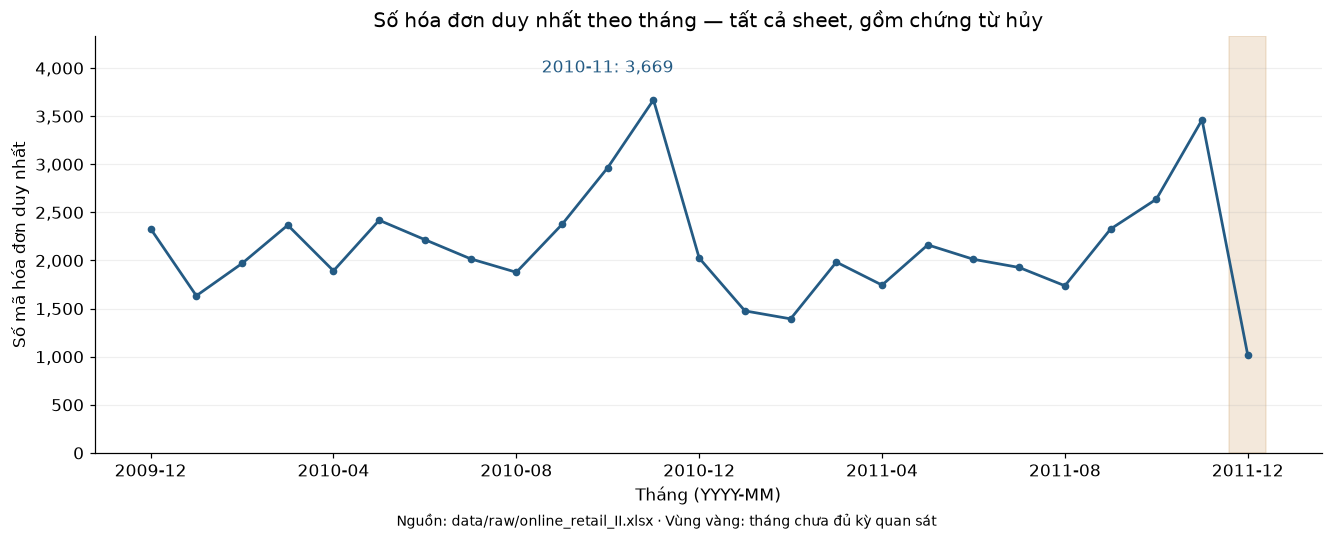

**Nhận xét.** Tháng nhiều mã hóa đơn nhất là 2010-11 (3.669); trong các tháng nằm trọn phạm vi quan sát, thấp nhất là 2011-02 (1.393). Biến động tháng kề nhau lớn nhất theo tỷ lệ là 2011-03 (+42.35%), giảm mạnh nhất là 2010-12 (-44.81%). Tháng cuối chỉ có dữ liệu đến 09/12/2011, nên không so trực tiếp với tháng đầy đủ. Đây là biến động quan sát được, chưa chứng minh nguyên nhân hoặc tính mùa vụ lặp lại.

In [12]:
fig, ax = plt.subplots(figsize=(12, 4.8), layout='constrained')
x_positions = np.arange(len(monthly))
counts = monthly['Số hóa đơn duy nhất']
ax.plot(x_positions, counts, color=BLUE, marker='o', markersize=4, linewidth=1.8)
for position, status in enumerate(monthly['Trạng thái']):
    if status == 'Ngoài phạm vi đủ tháng':
        ax.axvspan(position - 0.4, position + 0.4, color=GOLD, alpha=0.15)
ticks = np.linspace(0, len(monthly) - 1, min(7, len(monthly)), dtype=int).tolist()
ax.set_xticks(ticks, [str(monthly.index[position]) for position in ticks])
ax.set(xlabel='Tháng (YYYY-MM)', ylabel='Số mã hóa đơn duy nhất', ylim=(0, counts.max() * 1.18),
       title='Số hóa đơn duy nhất theo tháng — tất cả sheet, gồm chứng từ hủy')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='y', alpha=0.2)
peak_month = counts.idxmax()
peak_position = monthly.index.get_loc(peak_month)
ax.annotate(f'{peak_month}: {counts.max():,.0f}', xy=(peak_position, counts.max()),
            xytext=(-30, 18), textcoords='offset points', ha='center', color=BLUE)
fig.supxlabel('Nguồn: data/raw/online_retail_II.xlsx · Vùng vàng: tháng chưa đủ kỳ quan sát', fontsize=9)
plt.show()

complete_months = monthly[monthly['Trạng thái'].eq('Trong phạm vi quan sát cả tháng')]
complete_counts = complete_months['Số hóa đơn duy nhất']
monthly_changes = complete_counts.pct_change(fill_method=None).dropna()
note(f'Tháng nhiều mã hóa đơn nhất là {peak_month} ({vn_int(counts.max())}); '
     f'trong các tháng nằm trọn phạm vi quan sát, thấp nhất là {complete_counts.idxmin()} ({vn_int(complete_counts.min())}). '
     f'Biến động tháng kề nhau lớn nhất theo tỷ lệ là {monthly_changes.idxmax()} ({monthly_changes.max():+.2%}), '
     f'giảm mạnh nhất là {monthly_changes.idxmin()} ({monthly_changes.min():+.2%}). '
     f'Tháng cuối chỉ có dữ liệu đến {date_max:%d/%m/%Y}, nên không so trực tiếp với tháng đầy đủ. '
     'Đây là biến động quan sát được, chưa chứng minh nguyên nhân hoặc tính mùa vụ lặp lại.')

## 7. Phân tích theo quốc gia

Tính số mã hóa đơn khác nhau **bên trong từng nhãn quốc gia** sau trim;
không lọc hủy, lượng/giá âm, dòng trùng hay thiếu mã khách hàng.
Kiểm tra hóa đơn nhiều quốc gia trước khi diễn giải tỷ trọng.
Nếu một mã thuộc nhiều quốc gia, tổng số đếm theo quốc gia sẽ lớn hơn tổng mã hóa đơn;
tỷ lệ dưới đây dùng mẫu số là **tổng cặp (quốc gia, hóa đơn)**, không phải tỷ trọng đơn hàng độc quyền.

In [13]:
country_eligible = eda['CountryKey'].notna() & eda['InvoiceKey'].notna()
country_pairs = eda.loc[country_eligible, ['CountryKey', 'InvoiceKey']].drop_duplicates()
country_counts = country_pairs.groupby('CountryKey')['InvoiceKey'].nunique().sort_values(ascending=False)
n_country_pairs = int(country_counts.sum())
country_table = country_counts.rename('Số hóa đơn duy nhất trong quốc gia').to_frame()
country_table['Tỷ trọng cặp quốc gia–hóa đơn (%)'] = country_counts / n_country_pairs * 100
show_table(country_table.reset_index(names='Quốc gia'), {'Tỷ trọng cặp quốc gia–hóa đơn (%)': '{:.3f}'})
note(f'Có {vn_int((~country_eligible).sum())} dòng thiếu quốc gia/mã hóa đơn không được nhóm; '
     f'{vn_int(n_country_pairs)} cặp quốc gia–hóa đơn so với {vn_int(n_invoices)} mã hóa đơn toàn cục. '
     f'{vn_int(len(multi_country))} mã gắn nhiều quốc gia; tỷ trọng dùng mẫu số {vn_int(n_country_pairs)} cặp để tránh giả định nhóm loại trừ nhau.')

Quốc gia,Số hóa đơn duy nhất trong quốc gia,Tỷ trọng cặp quốc gia–hóa đơn (%)
United Kingdom,49108,91.572
Germany,1095,2.042
EIRE,806,1.503
France,746,1.391
Netherlands,250,0.466
Spain,188,0.351
Belgium,183,0.341
Sweden,129,0.241
Portugal,124,0.231
Switzerland,123,0.229


**Nhận xét.** Có 0 dòng thiếu quốc gia/mã hóa đơn không được nhóm; 53.628 cặp quốc gia–hóa đơn so với 53.628 mã hóa đơn toàn cục. 0 mã gắn nhiều quốc gia; tỷ trọng dùng mẫu số 53.628 cặp để tránh giả định nhóm loại trừ nhau.

**Nhận xét.** Không phát hiện mã hóa đơn gắn nhiều quốc gia theo phép kiểm tra trên toàn bộ workbook.

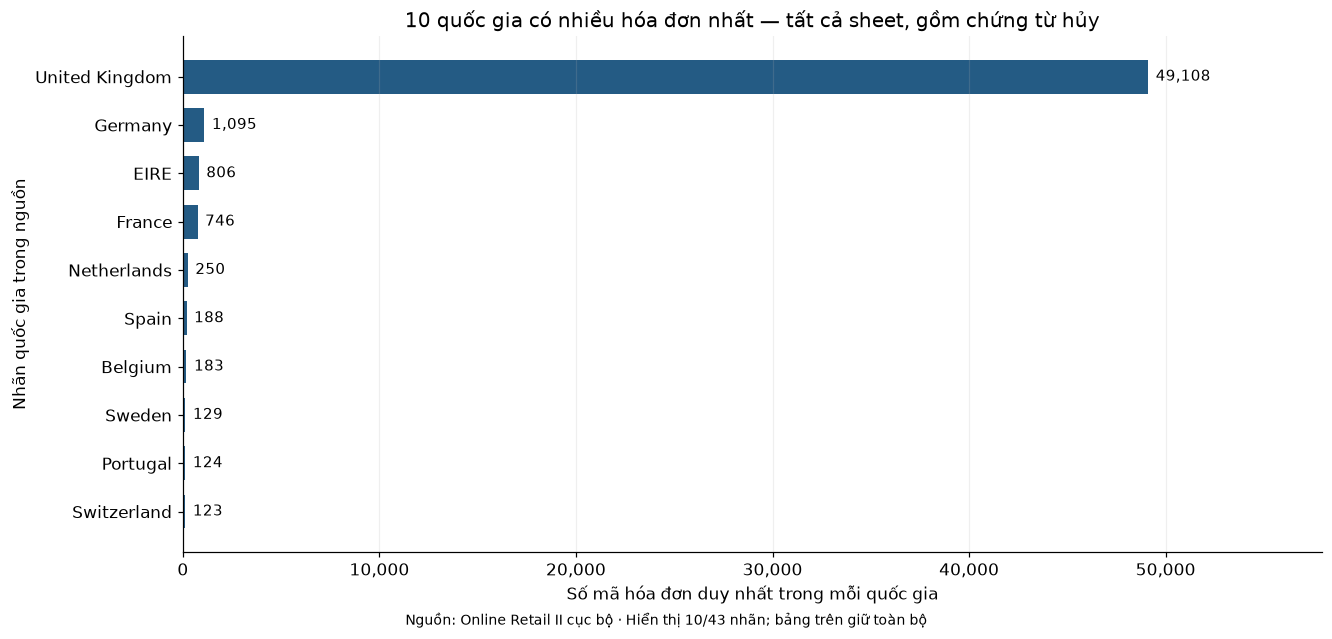

**Nhận xét.** United Kingdom đứng đầu với 49.108 mã hóa đơn, chiếm 91.57% các cặp quốc gia–hóa đơn; 10 nhãn đầu chiếm 98.37%. Giao dịch tập trung mạnh vào nhãn đứng đầu. Chưa suy rộng thành cơ cấu thị trường hiện tại hoặc giá trị/khả năng sinh lời của khách hàng.

In [14]:
if len(multi_country):
    country_conflicts = eda.loc[eda['InvoiceKey'].isin(multi_country.index)].groupby('InvoiceKey').agg(
        Countries=('CountryKey', lambda values: ', '.join(sorted(values.dropna().unique()))),
        Customers=('Customer ID', 'nunique'), Rows=('InvoiceKey', 'size'),
        FirstDate=('InvoiceDateParsed', 'min'), LastDate=('InvoiceDateParsed', 'max'),
    ).reset_index()
    show_table(country_conflicts.head(10))
    note('Hiển thị tối đa 10 mã hóa đơn có quốc gia mâu thuẫn để bàn giao kiểm tra. '
         'Không tự chọn một quốc gia hay ghép khóa với Customer ID để che mâu thuẫn.')
else:
    note('Không phát hiện mã hóa đơn gắn nhiều quốc gia theo phép kiểm tra trên toàn bộ workbook.')

top_countries = country_counts.head(10).sort_values()
fig, ax = plt.subplots(figsize=(12, 5.7), layout='constrained')
bars = ax.barh(top_countries.index, top_countries.values, color=BLUE, height=0.7)
ax.bar_label(bars, labels=[f'{value:,}' for value in top_countries], padding=5, fontsize=10)
ax.set(xlabel='Số mã hóa đơn duy nhất trong mỗi quốc gia', ylabel='Nhãn quốc gia trong nguồn',
       title='10 quốc gia có nhiều hóa đơn nhất — tất cả sheet, gồm chứng từ hủy',
       xlim=(0, top_countries.max() * 1.18))
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='x', alpha=0.2)
fig.supxlabel(f'Nguồn: Online Retail II cục bộ · Hiển thị 10/{len(country_counts)} nhãn; bảng trên giữ toàn bộ', fontsize=9)
plt.show()
top_country = country_counts.index[0]
top_country_share = float(country_counts.iloc[0] / n_country_pairs)
top10_share = float(country_counts.head(10).sum() / n_country_pairs)
note(f'{top_country} đứng đầu với {vn_int(country_counts.iloc[0])} mã hóa đơn, '
     f'chiếm {top_country_share:.2%} các cặp quốc gia–hóa đơn; 10 nhãn đầu chiếm {top10_share:.2%}. '
     'Giao dịch tập trung mạnh vào nhãn đứng đầu. Chưa suy rộng thành cơ cấu thị trường hiện tại hoặc giá trị/khả năng sinh lời của khách hàng.')

## 8. Phân phối số lượng và đơn giá

### 8.1. Toàn bộ khoảng giá trị

Histogram dùng tất cả quan sát hữu hạn; biên bin cách đều trên phép biến đổi `sign(x) × log1p(|x|)`
để quan sát cả giá trị âm, 0 và đuôi lớn. Trục x là **symlog** với vùng tuyến tính quanh 0;
trục y là số dòng trên **thang log**. Chiều rộng bin trên thang số gốc không bằng nhau,
do đó không diễn giải chiều cao là mật độ theo đơn vị gốc. Không cắt hoặc winsorize dữ liệu.

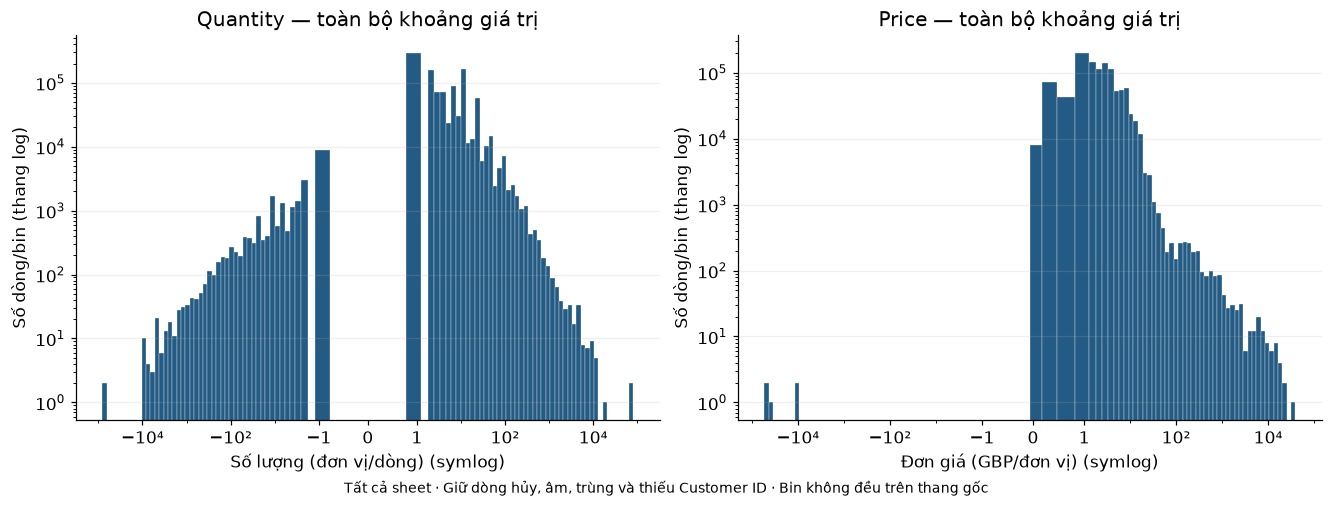

**Nhận xét.** Cả hai phân phối được hiển thị trên toàn bộ miền giá trị, kể cả dấu âm và 0. Đuôi dài giải thích vì sao trục tuyến tính toàn miền khó thể hiện phần tập trung; không lấy chiều cao các bin không đều làm mật độ và không coi thang log là thao tác làm sạch dữ liệu.

In [15]:
distribution_columns = [('Quantity', 'Số lượng (đơn vị/dòng)'), ('Price', 'Đơn giá (GBP/đơn vị)')]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
for ax, (column, label) in zip(axes, distribution_columns):
    values = eda[column].dropna()
    values = values[np.isfinite(values)]
    lo, hi = values.min(), values.max()
    transform = lambda value: np.sign(value) * np.log1p(np.abs(value))
    transformed_edges = np.linspace(transform(lo), transform(hi), 100)
    edges = np.sign(transformed_edges) * np.expm1(np.abs(transformed_edges))
    edges[0], edges[-1] = lo, hi  # bao gồm chính xác hai cực trị, tránh sai số nghịch biến đổi
    ax.hist(values, bins=edges, color=BLUE, edgecolor='white', linewidth=0.2)
    ax.set_xscale('symlog', linthresh=1)
    ax.set_xticks([-10000, -100, -1, 0, 1, 100, 10000])
    ax.set_xticklabels(['−10⁴', '−10²', '−1', '0', '1', '10²', '10⁴'])
    ax.set_yscale('log')
    ax.set(title=f'{column} — toàn bộ khoảng giá trị', xlabel=label + ' (symlog)', ylabel='Số dòng/bin (thang log)')
    ax.grid(axis='y', alpha=0.2)
fig.supxlabel('Tất cả sheet · Giữ dòng hủy, âm, trùng và thiếu Customer ID · Bin không đều trên thang gốc', fontsize=9)
plt.show()
note('Cả hai phân phối được hiển thị trên toàn bộ miền giá trị, kể cả dấu âm và 0. '
     'Đuôi dài giải thích vì sao trục tuyến tính toàn miền khó thể hiện phần tập trung; '
     'không lấy chiều cao các bin không đều làm mật độ và không coi thang log là thao tác làm sạch dữ liệu.')

### 8.2. Histogram phóng to P01–P99 và boxplot toàn bộ dữ liệu

Histogram tiếp theo chỉ vẽ phần trong khoảng P01–P99 tính trên dữ liệu gốc;
bảng ghi số dòng trong/ngoài vùng hiển thị. Đây là **giới hạn trực quan**, không tạo dữ liệu đã xóa ngoại lai.
Boxplot ở bên dưới vẫn tính từ toàn bộ giá trị, râu theo 1,5 × IQR; các điểm ngoài râu
là quy ước thống kê, chưa phải quyết định loại bỏ.

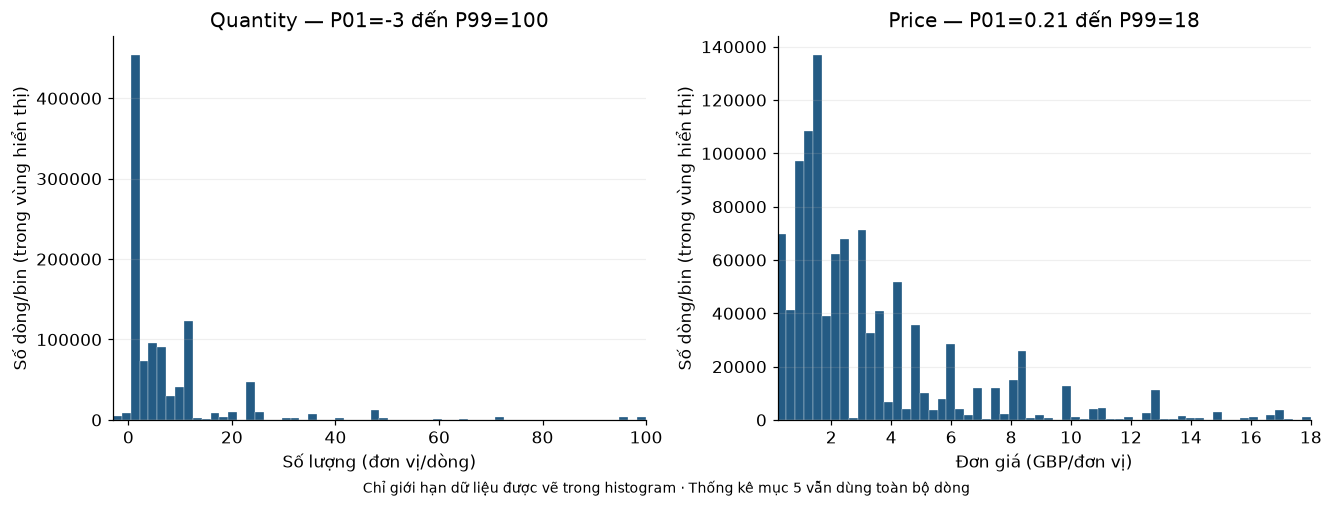

Biến,P01,P99,Dòng trong vùng,Dòng ngoài vùng,Ngoài vùng (%)
Quantity,-3.000,100.000,1047142,20229,1.895
Price,0.210,18.000,1046158,21213,1.987


**Nhận xét.** Quantity: 20.229 dòng ngoài vùng hiển thị (1.90%); Price: 21.213 dòng ngoài vùng hiển thị (1.99%). Các dòng này vẫn tồn tại trong raw, eda và mọi thống kê tổng thể. Tỷ lệ có thể khác 2% do phân phối rời rạc và các giá trị bằng ngưỡng.

In [16]:
zoom_records = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
for ax, (column, label) in zip(axes, distribution_columns):
    values = eda[column].dropna()
    lower, upper = values.quantile([0.01, 0.99])
    inside = values.between(lower, upper)
    ax.hist(values[inside], bins=60, color=BLUE, edgecolor='white', linewidth=0.2)
    ax.set(title=f'{column} — P01={lower:g} đến P99={upper:g}', xlabel=label,
           ylabel='Số dòng/bin (trong vùng hiển thị)', xlim=(lower, upper))
    ax.grid(axis='y', alpha=0.2)
    zoom_records.append({'Biến': column, 'P01': lower, 'P99': upper,
                         'Dòng trong vùng': int(inside.sum()), 'Dòng ngoài vùng': int((~inside).sum()),
                         'Ngoài vùng (%)': (~inside).mean() * 100})
fig.supxlabel('Chỉ giới hạn dữ liệu được vẽ trong histogram · Thống kê mục 5 vẫn dùng toàn bộ dòng', fontsize=9)
plt.show()
zoom_summary = pd.DataFrame(zoom_records)
show_table(zoom_summary, {'Ngoài vùng (%)': '{:.3f}', 'P01': '{:,.3f}', 'P99': '{:,.3f}'})
note('; '.join(f"{row['Biến']}: {vn_int(row['Dòng ngoài vùng'])} dòng ngoài vùng hiển thị ({row['Ngoài vùng (%)']:.2f}%)"
               for row in zoom_records) + '. Các dòng này vẫn tồn tại trong raw, eda và mọi thống kê tổng thể. '
     'Tỷ lệ có thể khác 2% do phân phối rời rạc và các giá trị bằng ngưỡng.')

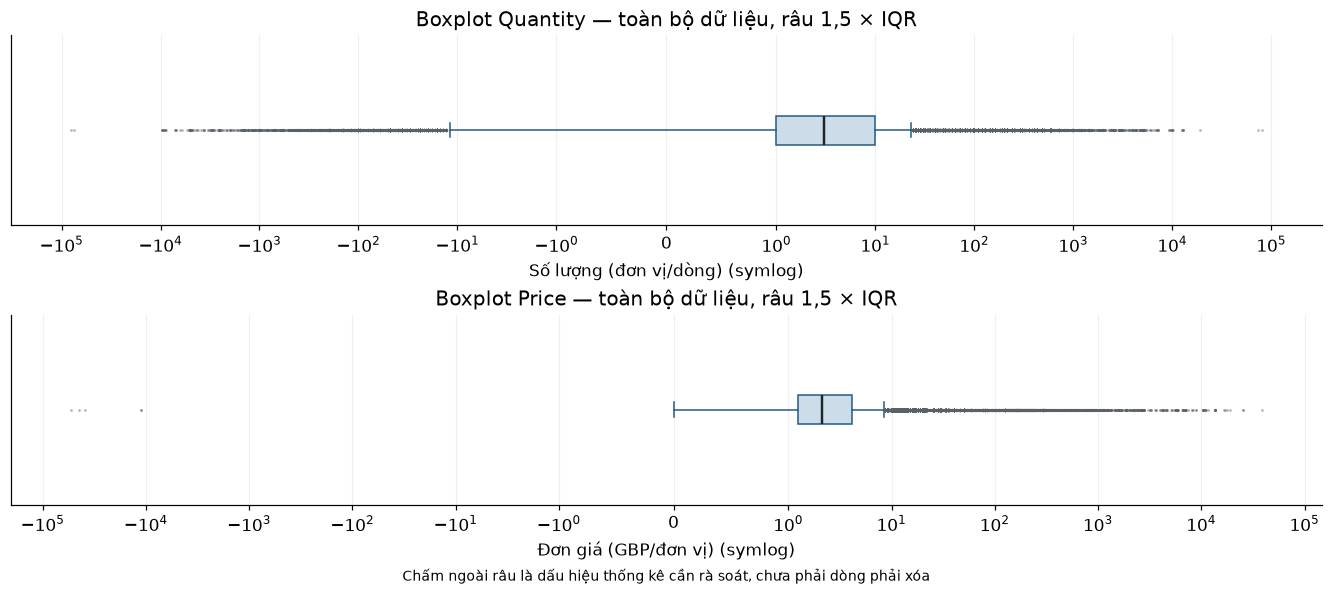

**Nhận xét.** Boxplot dùng toàn bộ quan sát và vẫn hiển thị điểm ngoài râu. Trung vị và hộp bị nén bởi đuôi dài ngay cả khi dùng symlog; histogram P01–P99 giúp đọc phần tập trung. Chính sách ngoại lai cần cân nhắc khách hàng mua sỉ và các bút toán đặc biệt, không áp dụng máy móc râu boxplot.

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.3), layout='constrained')
for ax, (column, label) in zip(axes, distribution_columns):
    ax.boxplot(eda[column].dropna().to_numpy(), orientation='horizontal', patch_artist=True,
               boxprops={'facecolor': '#CCDCE8', 'edgecolor': BLUE},
               medianprops={'color': '#20252A', 'linewidth': 1.6},
               whiskerprops={'color': BLUE}, capprops={'color': BLUE},
               flierprops={'marker': '.', 'markersize': 2, 'markerfacecolor': GRAY, 'markeredgecolor': GRAY, 'alpha': 0.3})
    ax.set_xscale('symlog', linthresh=1)
    ax.set(title=f'Boxplot {column} — toàn bộ dữ liệu, râu 1,5 × IQR', xlabel=label + ' (symlog)', yticks=[])
    ax.grid(axis='x', alpha=0.2)
fig.supxlabel('Chấm ngoài râu là dấu hiệu thống kê cần rà soát, chưa phải dòng phải xóa', fontsize=9)
plt.show()
note('Boxplot dùng toàn bộ quan sát và vẫn hiển thị điểm ngoài râu. '
     'Trung vị và hộp bị nén bởi đuôi dài ngay cả khi dùng symlog; histogram P01–P99 giúp đọc phần tập trung. '
     'Chính sách ngoại lai cần cân nhắc khách hàng mua sỉ và các bút toán đặc biệt, không áp dụng máy móc râu boxplot.')

## 9. Kết luận EDA v1 và bàn giao

### 9.1. Tổng hợp kết quả đã tính

Các kết luận được sinh từ biến đã tính ở trên để thống nhất với kết quả chạy.

In [18]:
note(f'Dữ liệu gồm {vn_int(n_rows)} dòng, {len(original_columns)} cột nguồn từ {len(sheet_names)} sheet '
     f'({", ".join(sheet_names)}), giai đoạn {date_min:%d/%m/%Y}–{date_max:%d/%m/%Y}. '
     f'Nhận diện {vn_int(n_customers)} khách hàng theo mã hợp lệ về hình thức, {vn_int(n_invoices)} mã hóa đơn và '
     f'{n_countries} nhãn quốc gia. {top_country} chiếm {top_country_share:.2%} các cặp quốc gia–hóa đơn; '
     f'tháng đỉnh là {peak_month} ({vn_int(counts.max())} hóa đơn). '
     f'Các vấn đề chính: {vn_int(customer_missing)} dòng thiếu Customer ID, {vn_int(duplicate_excess)} dòng trùng dư '
     f'(trong đó tăng thêm {vn_int(cross_sheet_excess)} khi gộp), {vn_int(n_cancel_invoices)} mã hủy, '
     f'{vn_int(eda["Quantity"].lt(0).sum())} dòng lượng âm, {vn_int(eda["Price"].le(0).sum())} dòng giá không dương. '
     'Phân phối có đuôi dài và tháng cuối chưa trọn kỳ; chưa suy diễn nguyên nhân hoặc kết quả mô hình.')

**Nhận xét.** Dữ liệu gồm 1.067.371 dòng, 8 cột nguồn từ 2 sheet (Year 2009-2010, Year 2010-2011), giai đoạn 01/12/2009–09/12/2011. Nhận diện 5.942 khách hàng theo mã hợp lệ về hình thức, 53.628 mã hóa đơn và 43 nhãn quốc gia. United Kingdom chiếm 91.57% các cặp quốc gia–hóa đơn; tháng đỉnh là 2010-11 (3.669 hóa đơn). Các vấn đề chính: 243.007 dòng thiếu Customer ID, 34.335 dòng trùng dư (trong đó tăng thêm 22.202 khi gộp), 8.292 mã hủy, 22.950 dòng lượng âm, 6.207 dòng giá không dương. Phân phối có đuôi dài và tháng cuối chưa trọn kỳ; chưa suy diễn nguyên nhân hoặc kết quả mô hình.

### 9.2. Nội dung trao đổi với thành viên phụ trách tiền xử lý

| Nội dung | Ảnh hưởng đến RFM/phân cụm | Quyết định cần thống nhất |
|---|---|---|
| Thiếu Customer ID | Không gán dòng về khách hàng tin cậy | Có giữ cho EDA cấp hóa đơn và loại khỏi RFM hay dùng nguồn đối chiếu? Không điền cùng một mã cho mọi dòng thiếu. |
| Trùng trong sheet và chồng lấn giữa sheet | Có thể tăng Monetary và sai Frequency nếu đếm dòng | Phân biệt bản sao với nghiệp vụ lặp; chốt khóa kiểm tra và chính sách trùng trên 8 cột nguồn. |
| Hóa đơn hủy, lượng âm và giá không dương | Có thể đảo dấu Monetary, sai khái niệm lần mua gần nhất | Chọn giao dịch mua hợp lệ, cách đối trừ hoàn trả/hủy; không gộp tất cả dấu hiệu thành một quy tắc xóa. |
| Mã hàng dịch vụ/điều chỉnh, mô tả thiếu, mã hóa đơn ngoài mẫu | Có thể lẫn bưu phí hoặc điều chỉnh với hàng hóa | Lập danh mục nghiệp vụ và xem ví dụ chứng từ trước khi lọc. |
| Mâu thuẫn quốc gia/khách hàng/thời điểm của hóa đơn nếu có | Khóa hóa đơn có thể chưa đủ nhất quán | Đối chiếu nguồn, chưa tự sửa/gán nhãn thay thế. |
| Cực trị số lượng/giá và phân phối lệch | Nhạy với khoảng cách, chuẩn hóa và số cụm | EDA v2 so sánh các phương án trên bản sao; chưa xóa/winsorize khi nhóm chưa chốt. |
| Tháng cuối chưa đầy đủ; không có múi giờ | So sánh xu hướng/RFM có thể lệch theo cửa sổ | Chốt ngày tham chiếu, cửa sổ quan sát và cách xử lý kỳ không đầy đủ. |

### 9.3. Tiếp tục ở EDA v2 (dự kiến)

1. Kiểm tra sâu dòng trùng, các mã nghiệp vụ đặc biệt và cực trị theo hóa đơn/khách hàng.
2. So sánh độ nhạy khi xử lý hủy/hoàn trả, giá không dương và ngoại lai theo chính sách nhóm thống nhất.
3. Khảo sát phân phối RFM **sau khi** có tập giao dịch và định nghĩa R/F/M được xác nhận;
   xem log/chuẩn hóa và ảnh hưởng đến KMeans, Ward, DBSCAN theo định hướng bộ khung.
4. Nếu mở rộng sang dự đoán giá trị tương lai, cần thiết kế nhãn và chia thời gian để tránh rò rỉ;
   EDA v1 chưa xác nhận định nghĩa “khách hàng giá trị cao” hay khả năng dự báo.

### 9.4. Giới hạn

Không suy ra lợi nhuận, hành vi ngoài cửa hàng, nhân khẩu học hoặc nguyên nhân biến động từ 8 cột nguồn.
Phân cụm trên lịch sử không tự trở thành dự đoán giá trị tương lai.
Chưa có tài liệu kế hoạch chi tiết, tên chính thức 5 chương hoặc tiêu chí khách hàng giá trị cao trong repository;
cần nhóm xác nhận. EDA v1 không sửa các module, notebook hoặc cấu hình của thành viên khác.

## 10. Kiểm tra nhất quán và cách chạy lại trên Windows

Các kiểm tra bên dưới xác minh phép gộp, số đếm độc lập, phạm vi hiển thị và checksum dữ liệu gốc.
Không kiểm tra bằng cách chỉ so hai bảng dùng cùng một phép tính.

In [19]:
# Đếm độc lập bằng các tập khóa, thay cho groupby/nunique đã dùng ở trên.
assert sum(sheet_profile['Số dòng']) == len(raw)
assert n_invoices == len(set(eda['InvoiceKey'].dropna()))
assert n_cancel_invoices == len(set(eda.loc[cancelled, 'InvoiceKey'].dropna()))
assert n_country_pairs == len(set(zip(country_pairs['CountryKey'], country_pairs['InvoiceKey'])))
invoice_month_pairs = set(zip(eda.loc[time_eligible, 'InvoiceDateParsed'].dt.strftime('%Y-%m'), eda.loc[time_eligible, 'InvoiceKey']))
assert int(monthly['Số hóa đơn duy nhất'].sum()) == len(invoice_month_pairs)
assert duplicate_excess == n_rows - len(raw.drop_duplicates(subset=original_columns))
assert cross_sheet_excess >= 0
assert all(row['Dòng trong vùng'] + row['Dòng ngoài vùng'] == int(eda[row['Biến']].notna().sum()) for row in zoom_records)
assert all(np.isfinite(eda[column].dropna()).all() for column in ['Quantity', 'Price', 'LineValue'])
assert source_hash_before == sha256(DATA_PATH), 'Checksum nguồn thay đổi trong lần chạy!'
print('Các kiểm tra nhất quán đều đạt. Dữ liệu gốc giữ nguyên trong lần chạy.')
print('SHA256:', source_hash_before)

# Bản ghi tổng hợp trong bộ nhớ để đối chiếu báo cáo/bàn giao; không ghi thêm tệp dữ liệu.
evidence = {
    'source_sha256': source_hash_before, 'environment': environment,
    'sheets': sheet_profile.assign(Từ=sheet_profile['Từ'].astype(str), Đến=sheet_profile['Đến'].astype(str)).to_dict('records'),
    'rows': n_rows, 'columns': original_columns, 'customers': n_customers,
    'invoices': n_invoices, 'countries': n_countries, 'stockcodes': n_stockcodes,
    'date_min': str(date_min), 'date_max': str(date_max),
    'missing': missing.to_dict('records'), 'quality': quality_counts.to_dict('records'),
    'duplicates_excess': duplicate_excess, 'duplicates_members': duplicate_members,
    'duplicates_within_sheet': within_sheet_excess, 'duplicates_cross_sheet_excess': cross_sheet_excess,
    'cross_sheet_patterns': cross_sheet_patterns, 'shared_invoices': shared_invoice_count,
    'other_checks': other_checks.to_dict('records'), 'customer_invalid_nonmissing': customer_invalid_nonmissing,
    'date_missing': date_missing, 'date_invalid': date_invalid,
    'descriptive': descriptive.reset_index(names='Biến').to_dict('records'),
    'monthly': monthly_view.to_dict('records'),
    'country': country_table.reset_index(names='Quốc gia').to_dict('records'),
    'country_pairs': n_country_pairs, 'top_country_share': top_country_share, 'top10_share': top10_share,
    'zoom': zoom_records,
}

Các kiểm tra nhất quán đều đạt. Dữ liệu gốc giữ nguyên trong lần chạy.
SHA256: bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980


### Chạy lại (PowerShell, từ thư mục gốc repository)

Môi trường `.venv-eda` tách riêng môi trường `.venv` đang có. Dùng Python 3.12
để khớp phiên bản đã kiểm tra; không cần kích hoạt môi trường nên không phụ thuộc ExecutionPolicy.
Nếu đã có `.venv-eda` với đủ thư viện, bỏ qua hai lệnh cài đặt đầu.

```powershell
py -3.12 -m venv project\.venv-eda
.\project\.venv-eda\Scripts\python.exe -m pip install -r project\requirements.txt
.\project\.venv-eda\Scripts\python.exe -m nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=900 project\notebooks\01_eda\eda_v1.ipynb
```

Máy dùng `uv` có thể tạo môi trường bằng `uv venv --python 3.12 project\.venv-eda`
và cài bằng `uv pip install --python project\.venv-eda\Scripts\python.exe -r project\requirements.txt`.

Mở tương tác:

```powershell
.\project\.venv-eda\Scripts\python.exe -m jupyterlab project\notebooks\01_eda\eda_v1.ipynb
```

Chọn kernel thuộc `.venv-eda` (nếu IDE chọn môi trường khác), rồi **Restart Kernel → Run All**.
Đọc Excel có thể mất vài phút. Các bảng, biểu đồ và nhận xét được tính lại từ tệp gốc;
notebook không ghi vào `data/raw/`, `data/interim/` hay `data/processed/`.